# Clustering Lab

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(
    "/Users/christinelezama/Downloads/fb_firm_posts (1).csv"
)

posts = df[df["post_type"].isin(["video", "photo"])].copy()
posts["firm_id"] = posts["post_id"].str.split("_").str[0]

topFirm = posts["firm_id"].value_counts().idxmax()
firmPosts = posts[posts["firm_id"] == topFirm].copy()

print("Firm ID:", topFirm)
print("Total posts:", len(firmPosts))
print(firmPosts["post_type"].value_counts())

print("\nMedian engagement:")
print(firmPosts[["num_likes", "num_comments", "num_shares"]].median())

Firm ID: 246675545449582
Total posts: 2466
post_type
photo    1869
video     597
Name: count, dtype: int64

Median engagement:
num_likes       101.0
num_comments      6.0
num_shares        2.0
dtype: float64


Firm 246675545449582 had the most photo and video posts, with 1,869 photos and 597 videos. The typical post got 101 likes, 6 comments, and 2 shares, so people liked posts much more often than they commented or shared them.

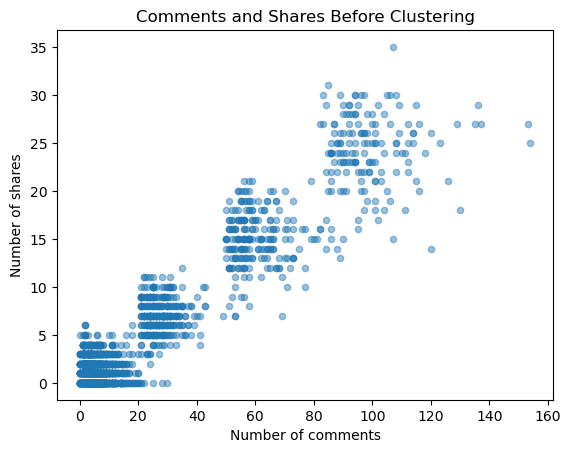

In [8]:
X = firmPosts[["num_comments", "num_shares"]].copy()

X.plot.scatter(
    x="num_comments",
    y="num_shares",
    alpha=0.45,
    title="Comments and Shares Before Clustering"
)

plt.xlabel("Number of comments")
plt.ylabel("Number of shares")
plt.show()

I can see about four groups. Most posts are packed near the bottom left, and three smaller groups appear as comments and shares increase.

In [15]:
print("Original ranges:")
print(X.agg(["min", "max"]))

scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)

print("\nMaximum standardized comments:")
print(round(X_scaled["num_comments"].max(), 4))

Original ranges:
     num_comments  num_shares
min             0           0
max           154          35

Maximum standardized comments:
4.983


3. Comments range from 0 to 154, while shares range from 0 to 35. Comments could have more influence on the distance calculation because they vary over a wider range. I used StandardScaler to put both variables on a comparable scale.

4. The maximum standardized value for num_comments is 4.9830.

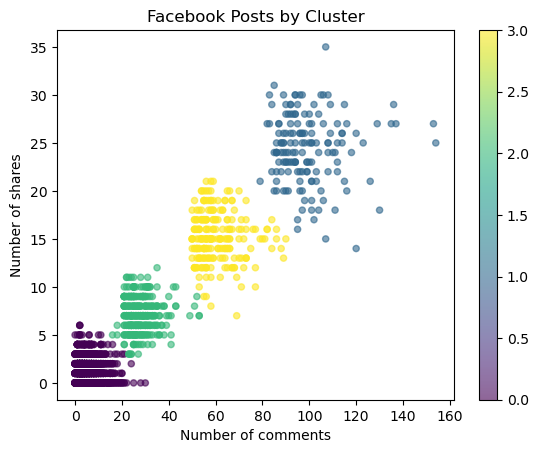

         posts  avg_comments  avg_shares
cluster                                 
0         1769           5.0         1.2
2          326          27.9         7.1
3          219          60.6        15.2
1          152          99.5        24.4


In [22]:
np.random.seed(42)

km = KMeans(n_clusters=4)
km.fit(X_scaled)
labels = km.labels_

X.plot.scatter(
    x="num_comments",
    y="num_shares",
    c=labels,
    colormap="viridis",
    alpha=0.6,
    title="Facebook Posts by Cluster"
)

plt.xlabel("Number of comments")
plt.ylabel("Number of shares")
plt.show()

clusterPosts = X.copy()
clusterPosts["cluster"] = labels

clusterSummary = clusterPosts.groupby("cluster").agg(
    posts=("num_comments", "size"),
    avg_comments=("num_comments", "mean"),
    avg_shares=("num_shares", "mean")
)

print(clusterSummary.sort_values("avg_comments").round(1))

The four groups look like low, moderate, high, and very high engagement. The biggest group averaged about 5 comments and 1 share per post, while the most engaged group averaged about 100 comments and 24 shares. Comments and shares generally went up together. I’d have the social media team review what the top posts had in common and test whether those same topics or formats work in future posts.

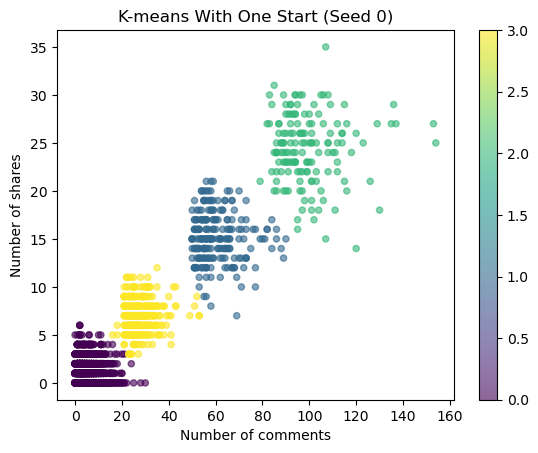

Seed: 0 | SSE: 258.99


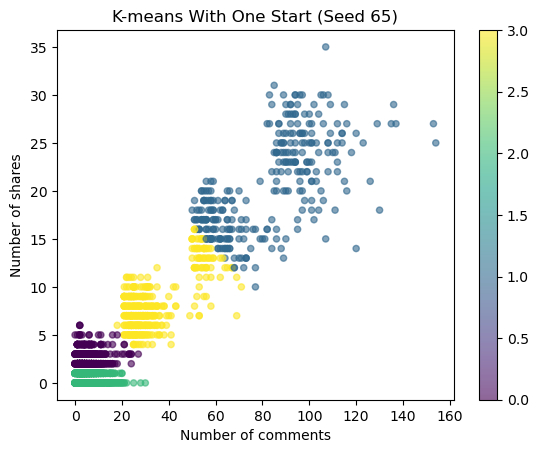

Seed: 65 | SSE: 545.16


In [25]:
for seed in [0, 65]:
    oneRun = KMeans(n_clusters=4, n_init=1, random_state=seed)
    oneRun.fit(X_scaled)

    X.plot.scatter(
        x="num_comments",
        y="num_shares",
        c=oneRun.labels_,
        colormap="viridis",
        alpha=0.6,
        title=f"K-means With One Start (Seed {seed})"
    )

    plt.xlabel("Number of comments")
    plt.ylabel("Number of shares")
    plt.show()

    print("Seed:", seed, "| SSE:", round(oneRun.inertia_, 2))

This is the initial centroid selection problem. K-means starts with a set of centroids and keeps updating them until the assignments settle. Different starting points can lead to different final groups, and one result can have a higher SSE than another. n_init controls how many times k-means starts over with a new set of centroids. With n_init=10, it tries 10 starts and keeps the result with the lowest SSE.

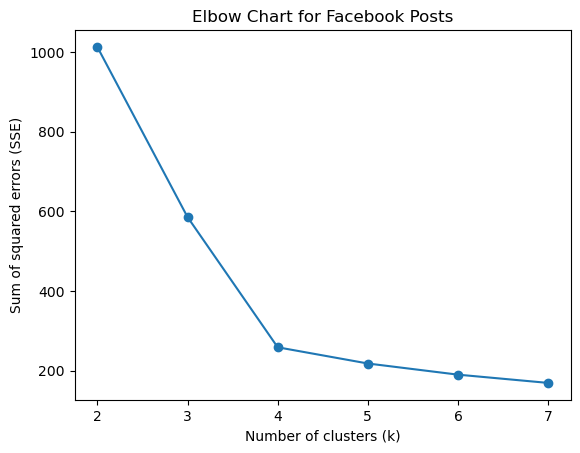

In [27]:
np.random.seed(42)

k_values = range(2, 8)
sse_values = []

for k in k_values:
    elbowModel = KMeans(n_clusters=k, n_init=10)
    elbowModel.fit(X_scaled)
    sse_values.append(elbowModel.inertia_)

plt.plot(k_values, sse_values, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (k)")
plt.ylabel("Sum of squared errors (SSE)")
plt.title("Elbow Chart for Facebook Posts")
plt.show()

I’d choose four clusters. The SSE drops sharply up to k = 4, and the line flattens after that. Adding more clusters still lowers the SSE, but by much less.

In [31]:
X_debug = firmPosts[["num_comments", "num_shares"]]

scaler = StandardScaler()
X_debug_scaled = scaler.fit_transform(X_debug)

km_debug = KMeans(n_clusters=4)
km_debug.fit(X_debug_scaled)

inertia_values = []

for k in range(2, 8):
    km_k = KMeans(n_clusters=k)
    km_k.fit(X_debug_scaled)
    inertia_values.append(km_k.inertia_)

print("Number of SSE values:", len(inertia_values))

Number of SSE values: 6


The first mistake was fitting the four-cluster model on the original data after scaling it. That lets comments have more influence on distance because they have a wider range. I changed the model to fit the scaled data. The second mistake was creating inertia_values inside the loop. That cleared the list every time, so only the last SSE was saved. Moving it above the loop keeps all six values.